# Gene Module Discovery

Genes don't act alone -- they work in coordinated groups. **Gene modules** are sets of genes whose expression co-varies across cells, often reflecting shared regulatory programs, pathways, or cell-state transitions. Discovering these modules from scRNA-seq data can reveal the biological processes that define each cell type and state.

PySingleCellNet provides a complete pipeline for gene module discovery:

1. **Build a gene-gene kNN graph** -- connect genes with similar expression profiles
2. **Cluster the graph** -- identify groups of co-expressed genes (modules)
3. **Score modules per cell** -- quantify how active each module is in every cell
4. **Visualize and interpret** -- heatmaps, UMAP overlays, and PC correlations

#### Data

We use the same 10k PBMC dataset (10X Genomics, v3 chemistry) featured in the other tutorials.
[Click here to download the processed data in h5ad](https://cnobjects.s3.amazonaws.com/singleCellNet/pySCN/resources/notebook_data/adPBMC_ref_040623.h5ad)

### Setting up

Import requisite packages

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import scanpy as sc
import pySingleCellNet as cn

Load the data

In [2]:
adata = sc.read_h5ad("../../data/adPBMC_ref_040623.h5ad")
adata.shape

(10309, 20104)

### Preprocessing

Standard scRNA-seq preprocessing: filter low-prevalence genes, normalize, log-transform, and identify highly variable genes (HVGs). We also run PCA and build a cell-level kNN graph for UMAP visualization later.

In [3]:
# Keep genes detected in at least 50 cells
sc.pp.filter_genes(adata, min_cells=50)

# Stash raw counts for later
adata.layers['counts'] = adata.X.copy()

# Normalize and log-transform
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

# Identify HVGs and run PCA
sc.pp.highly_variable_genes(adata, n_top_genes=2000, flavor='cell_ranger')
sc.tl.pca(adata, mask_var='highly_variable')

# Build cell-level kNN graph and UMAP
sc.pp.neighbors(adata, n_neighbors=15, n_pcs=20)
sc.tl.umap(adata)

print(f"Cells: {adata.n_obs:,}  Genes: {adata.n_vars:,}  HVGs: {adata.var['highly_variable'].sum():,}")

Cells: 10,309  Genes: 13,503  HVGs: 2,000


Cluster the cells so we have group labels (used later when building the gene graph). Then visualize the known cell type annotations alongside the Leiden clusters.

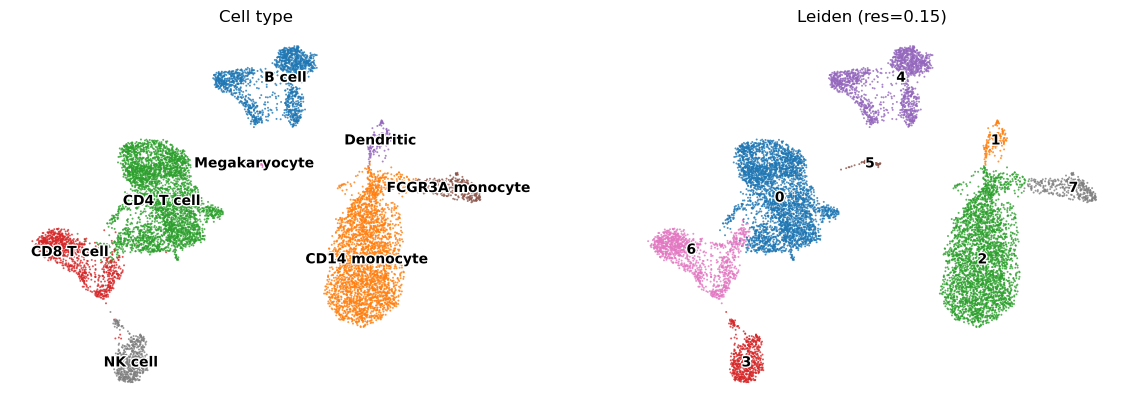

In [4]:
sc.tl.leiden(adata, resolution=0.15, flavor='igraph', n_iterations=2)
sc.pl.umap(
    adata,
    color=['cell_type', 'leiden'],
    frameon=False,
    legend_loc='on data',
    legend_fontoutline=2,
    s=8,
    alpha=0.8,
    ncols=2,
    title=['Cell type', 'Leiden (res=0.15)'],
)

---
## Step 1: Discover gene modules

### How it works

`find_gene_modules` builds a **kNN graph over genes** (not cells) and then clusters that graph with the Leiden algorithm. Two key decisions shape the result:

| Parameter | What it controls | Guidance |
|---|---|---|
| `mean_cluster` | Whether to average expression within cell clusters before computing gene-gene distances | **True** (default) reduces noise and speeds computation; **False** preserves single-cell resolution |
| `knn` | Number of nearest neighbors per gene in the gene graph | Higher values produce denser graphs and larger modules |
| `leiden_resolution` | Resolution of the Leiden clustering on the gene graph | Lower values yield fewer, larger modules; higher values yield more, smaller modules |
| `metric` | Distance metric for gene-gene similarity | `'euclidean'` (default) works well; `'correlation'` captures co-expression patterns regardless of magnitude |
| `mask_var` | Restrict analysis to a subset of genes (e.g. HVGs) | Focusing on HVGs is recommended to avoid modules driven by noise |

The result is a dictionary mapping module names (e.g. `gmod_0`, `gmod_1`, ...) to lists of gene names, stored in `adata.uns['knn_modules']`.

In [5]:
modules = cn.tl.find_gene_modules(
    adata,
    mean_cluster=True,
    groupby='leiden',
    mask_var='highly_variable',
    knn=5,
    leiden_resolution=0.5,
    metric='euclidean',
    uns_key='knn_modules',
    min_module_size=5,
)

print(f"Found {len(modules)} gene modules")
for name, genes in modules.items():
    print(f"  {name}: {len(genes)} genes  (top 5: {', '.join(genes[:5])})")

Found 18 gene modules
  gmod_0: 247 genes  (top 5: ARSK, CYP3A5, AC099778.1, ADAL, EPHA1-AS1)
  gmod_1: 208 genes  (top 5: BDP1, AC044849.1, CCDC66, ICE2, CFAP97)
  gmod_2: 190 genes  (top 5: BLVRB, NCF2, PSAP, NUP214, CXCL8)
  gmod_3: 188 genes  (top 5: REXO4, WDR73, LINC00685, MRPL1, ZNF26)
  gmod_4: 167 genes  (top 5: TMEM161B-AS1, ANKS3, AL031846.2, TTPAL, ZNF708)
  gmod_5: 153 genes  (top 5: PTPN4, GLS, GCC2, C1orf56, TMC8)
  gmod_6: 123 genes  (top 5: DUSP4, AP001267.1, FGF14-AS2, WDR66, AC005697.2)
  gmod_7: 117 genes  (top 5: MMP25-AS1, RNF165, CFH, TMIGD2, XCL1)
  gmod_8: 111 genes  (top 5: SMIM14, FAM129C, FCER2, TLR10, SP140)
  gmod_9: 100 genes  (top 5: PYCR2, NT5M, LINC01089, FAXDC2, MLH3)
  gmod_10: 78 genes  (top 5: RUFY1, LIMS1, MTURN, MMD, TUBA1C)
  gmod_11: 75 genes  (top 5: PDE4D, TMEM106C, HABP4, TARSL2, PBX1)
  gmod_12: 63 genes  (top 5: ICOSLG, AP001059.3, TNFRSF17, PMEPA1, MACROD2)
  gmod_13: 61 genes  (top 5: ZNF92, GPR18, RASGRP3, AC245060.5, RP9)
  gmod_14: 56

### Visualize module sizes

A quick overview of how many genes are in each module. A good partition typically has a mix of sizes -- a few large modules capturing broad programs and several smaller ones reflecting more specific signatures.

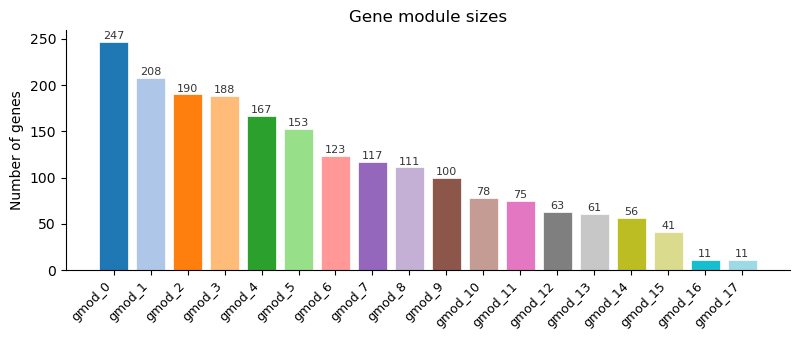

In [6]:
mod_sizes = pd.Series({k: len(v) for k, v in modules.items()}).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(max(6, len(mod_sizes) * 0.45), 3.5))
colors = plt.cm.tab20(np.linspace(0, 1, len(mod_sizes)))
bars = ax.bar(range(len(mod_sizes)), mod_sizes.values, color=colors, edgecolor='white', linewidth=0.5)
ax.set_xticks(range(len(mod_sizes)))
ax.set_xticklabels(mod_sizes.index, rotation=45, ha='right', fontsize=9)
ax.set_ylabel('Number of genes')
ax.set_title('Gene module sizes')
ax.spines[['top', 'right']].set_visible(False)

for bar, val in zip(bars, mod_sizes.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
            str(val), ha='center', va='bottom', fontsize=8, color='#333')

plt.tight_layout()
plt.show()

---
## Step 2: Score modules per cell

Now that we have gene modules, we want to know **how active** each module is in every cell. `score_gene_sets` computes a per-cell score for each module.

Two scoring paradigms are available:

| Approach | When to use | Key parameter |
|---|---|---|
| **Value-based** (default) | General purpose; works on normalized expression | `agg` -- aggregation method (`'mean'`, `'median'`, `'top_p_mean'`, etc.) |
| **Rank-based** (`rank_method='ucell'` or `'auc'`) | Robust to batch effects and normalization differences | `rank_method` -- `'ucell'` (Mann-Whitney U) or `'auc'` (AUCell) |

The value-based pipeline clips outliers, scales each gene to [0, 1], and aggregates across the module's genes. This produces intuitive scores where higher = more expression of the module.

Below, we score using the default value-based approach and also demonstrate rank-based UCell scoring.

In [7]:
# Value-based scoring (default)
scores_val = cn.tl.score_gene_sets(
    adata,
    gene_sets='knn_modules',
    agg='mean',
    clip_percentiles=(1, 99),
    obsm_name='module_scores',
)

print(f"Score matrix: {scores_val.shape[0]} cells x {scores_val.shape[1]} modules")
scores_val.head()

Score matrix: 10309 cells x 18 modules


,gmod_0,gmod_1,gmod_2,gmod_3,gmod_4,gmod_5,gmod_6,gmod_7,gmod_8,gmod_9,gmod_10,gmod_11,gmod_12,gmod_13,gmod_14,gmod_15,gmod_16,gmod_17
AAACCCAAGCGCCCAT-1,0.024291,0.181086,0.067533,0.072581,0.034855,0.207633,0.000000,0.063496,0.043496,0.036367,0.066536,0.026667,0.000000,0.030348,0.000000,0.147400,0.141203,0.0
AAACCCAAGGTTCCGC-1,0.010667,0.081237,0.342882,0.076600,0.027299,0.085327,0.002977,0.010717,0.129814,0.053771,0.092719,0.008123,0.003756,0.012815,0.000000,0.011557,0.886505,0.0
AAACCCACAGAGTTGG-1,0.000000,0.051195,0.445726,0.033036,0.028726,0.041563,0.000000,0.004417,0.050817,0.047164,0.054019,0.008847,0.029442,0.029724,0.016673,0.019511,0.107977,0.0
AAACCCACAGGTATGG-1,0.024098,0.164928,0.125487,0.133403,0.047003,0.391495,0.008130,0.192705,0.038793,0.050817,0.070015,0.060339,0.000000,0.053741,0.000000,0.035134,0.013727,0.0
AAACCCACATAGTCAC-1,0.043386,0.134403,0.084998,0.148192,0.037052,0.147044,0.008130,0.011553,0.395724,0.070036,0.097657,0.023848,0.152192,0.163037,0.017857,0.000000,0.568329,0.0


In [8]:
# Rank-based scoring with UCell (robust alternative)
scores_ucell = cn.tl.score_gene_sets(
    adata,
    gene_sets='knn_modules',
    rank_method='ucell',
    obsm_name='module_scores_ucell',
)

scores_ucell.head()

,gmod_0,gmod_1,gmod_2,gmod_3,gmod_4,gmod_5,gmod_6,gmod_7,gmod_8,gmod_9,gmod_10,gmod_11,gmod_12,gmod_13,gmod_14,gmod_15,gmod_16,gmod_17
AAACCCAAGCGCCCAT-1,0.479990,0.539642,0.517720,0.510736,0.490744,0.616499,0.488647,0.469771,0.466908,0.433667,0.492697,0.432350,0.509732,0.471224,0.459085,0.421068,0.539431,0.373514
AAACCCAAGGTTCCGC-1,0.356701,0.485063,0.788558,0.476315,0.391952,0.533800,0.365972,0.350836,0.572115,0.403830,0.502425,0.330042,0.391547,0.366510,0.342902,0.269791,0.996671,0.278791
AAACCCACAGAGTTGG-1,0.432737,0.458624,0.804569,0.466442,0.459878,0.468730,0.452153,0.416524,0.467773,0.433775,0.492959,0.404190,0.492268,0.441239,0.435657,0.345578,0.509406,0.350241
AAACCCACAGGTATGG-1,0.428516,0.542021,0.556945,0.540534,0.462939,0.766220,0.442085,0.541079,0.446202,0.428144,0.475036,0.437585,0.463987,0.442575,0.417609,0.332852,0.323505,0.339561
AAACCCACATAGTCAC-1,0.463367,0.514182,0.527321,0.530463,0.469961,0.561892,0.473555,0.431963,0.692596,0.461668,0.500734,0.420953,0.566247,0.533332,0.460636,0.314381,0.914057,0.356737


---
## Step 3: Visualize module activity

### Module scores on the UMAP

Overlay each module's activity on the cell embedding. Modules with cell-type-specific activity will light up distinct regions of the UMAP.

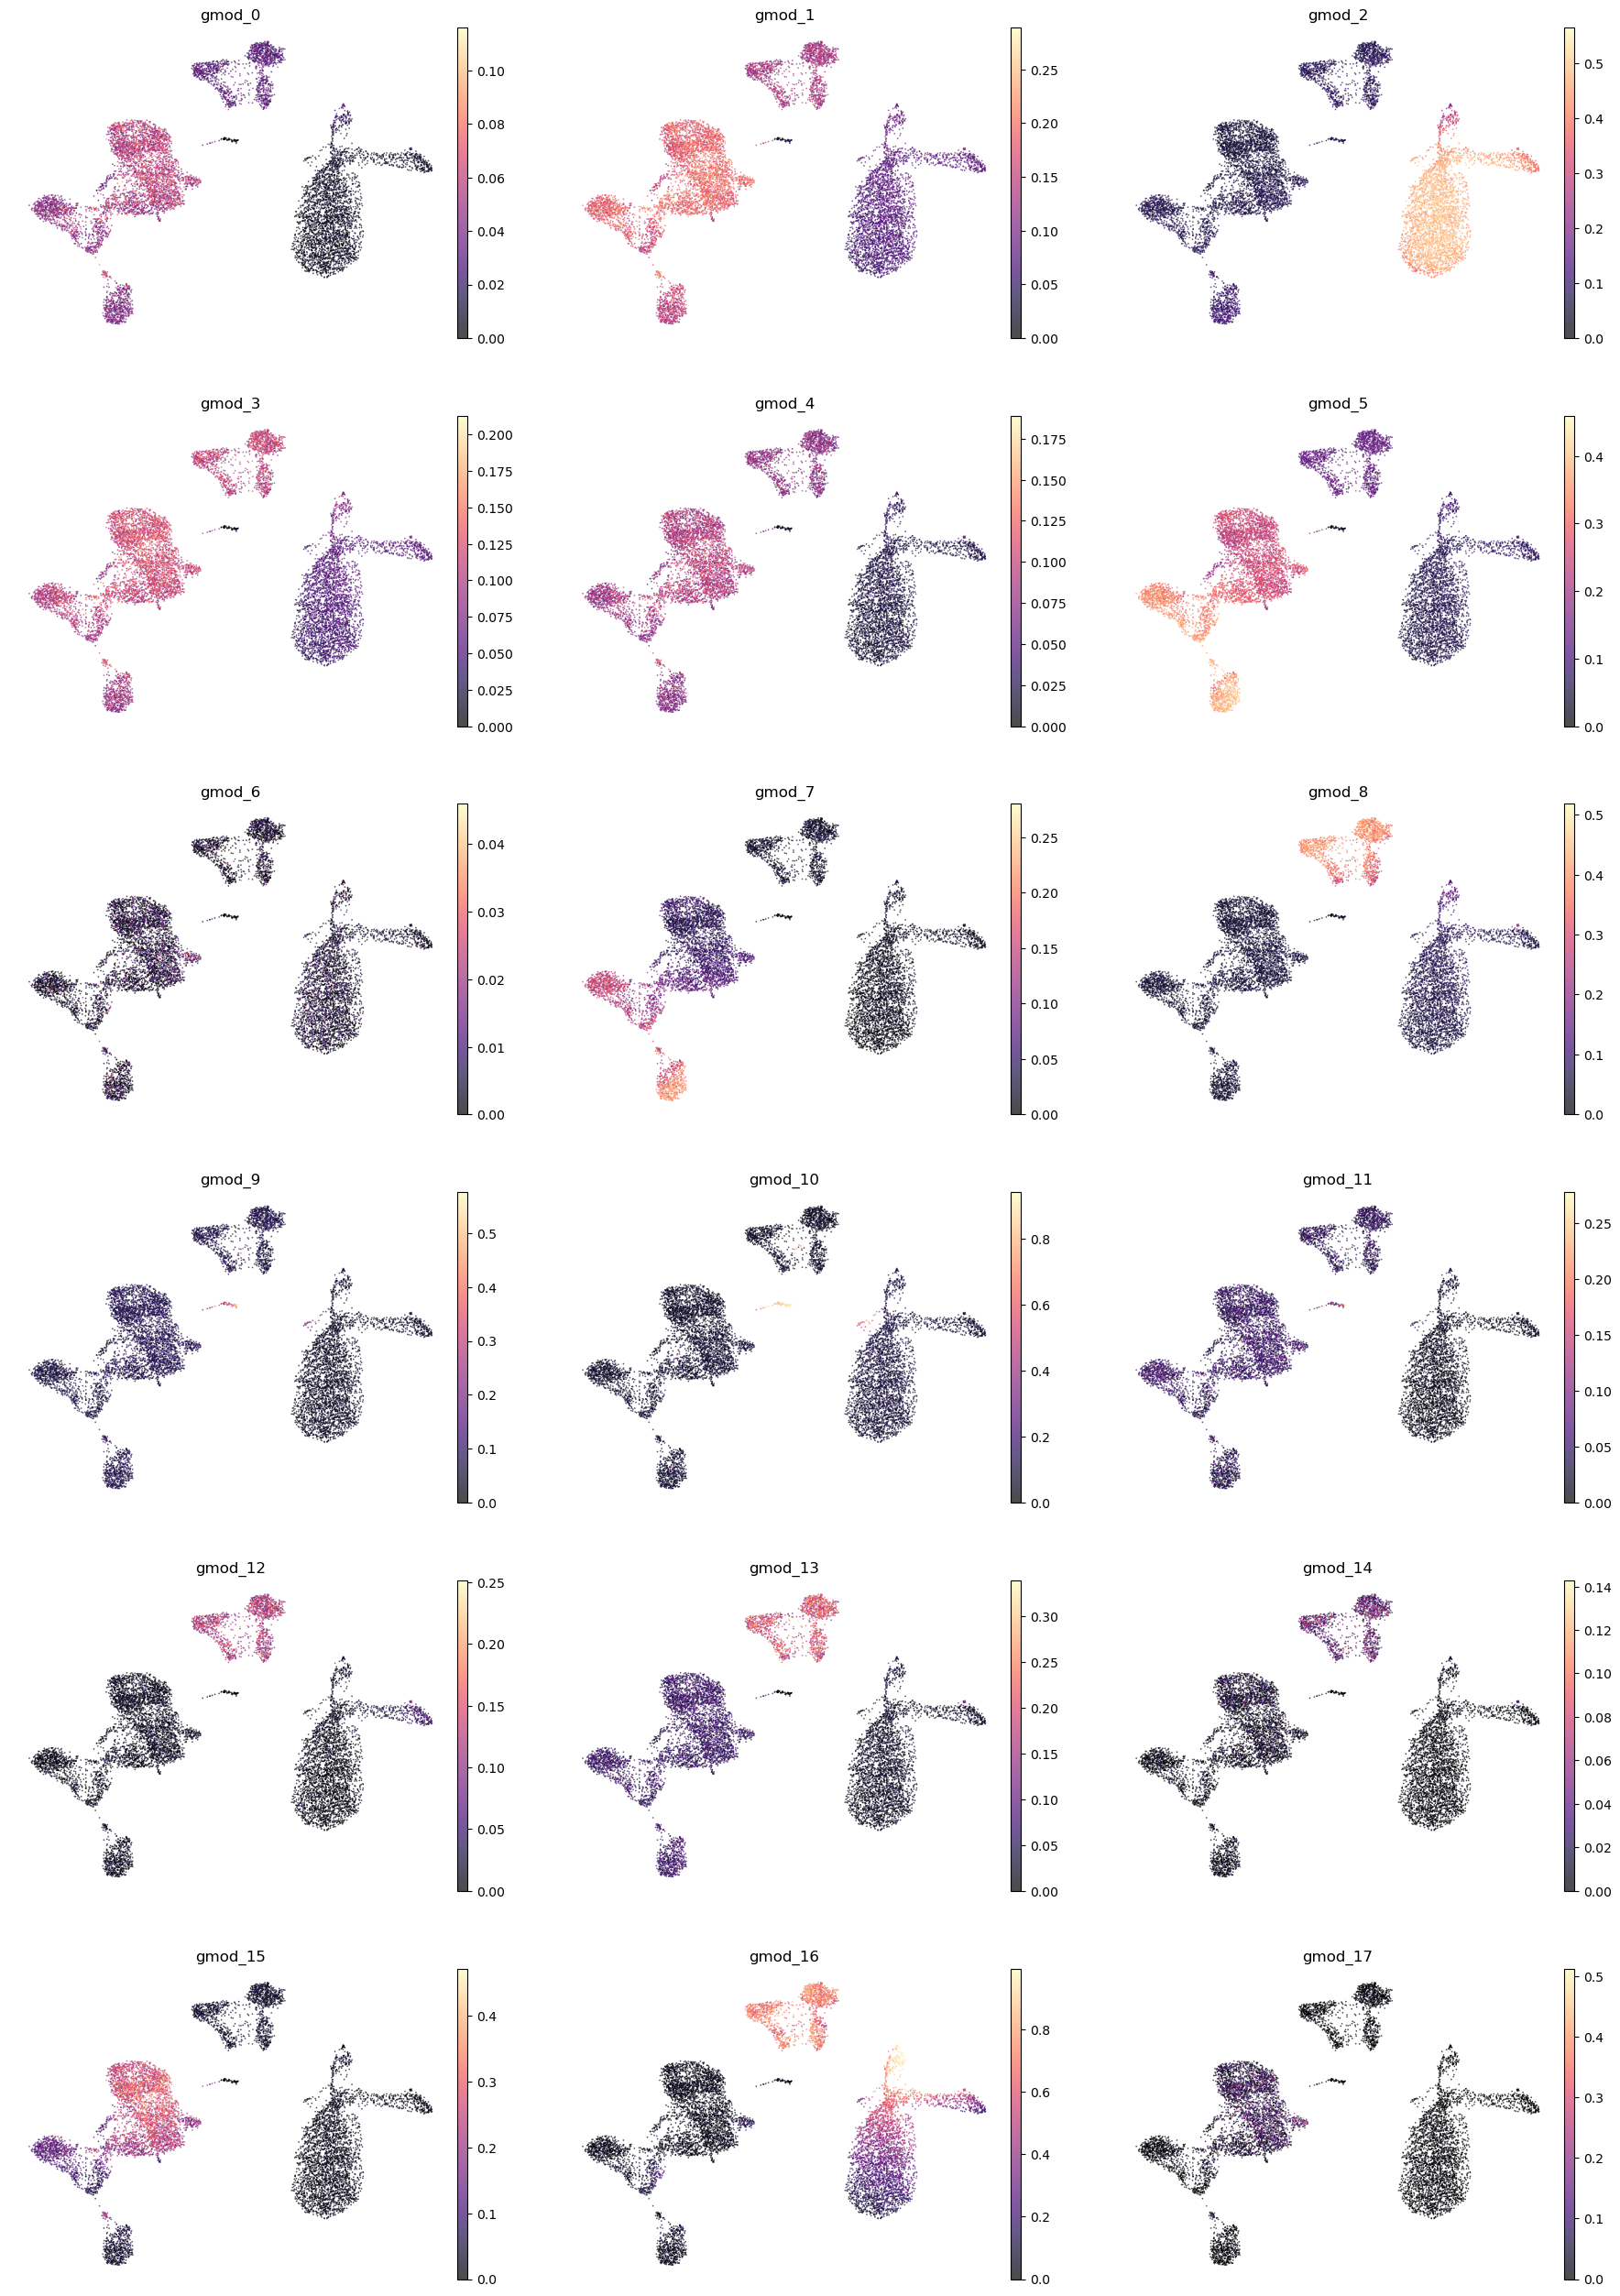

In [9]:
# Transfer module scores to adata.obs for scanpy plotting
# Use a 'score_' prefix to avoid collision with gene names in adata.var
obs_score_names = []
for col in scores_val.columns:
    obs_name = f"score_{col}"
    adata.obs[obs_name] = scores_val[col].values
    obs_score_names.append(obs_name)

module_names = list(modules.keys())
sc.pl.umap(
    adata,
    color=obs_score_names,
    frameon=False,
    ncols=3,
    s=6,
    alpha=0.7,
    cmap='magma',
    vmin=0,
    title=module_names,
)

### Heatmap of module scores across cell types

A heatmap summarizing mean module activity per cell type provides a compact overview of which biological programs are active in which populations.

/opt/homebrew/Caskroom/miniforge/base/envs/autocluster/lib/python3.12/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


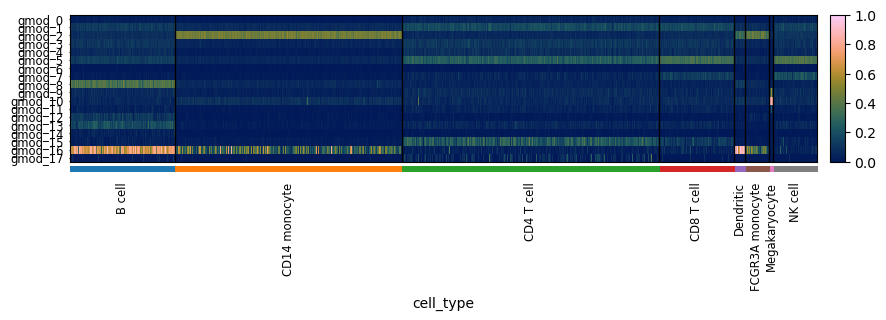

In [10]:
cn.pl.heatmap_scores(
    adata,
    groupby='cell_type',
    obsm_name='module_scores',
    vmin=0,
    vmax=1,
)

### Dotplot of module scores

The dotplot encodes both the magnitude (color) and the fraction of cells expressing (dot size) for each module in each cell type.

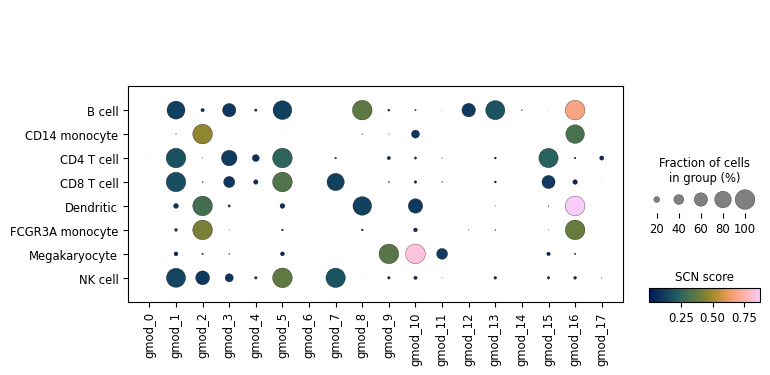

In [11]:
cn.pl.dotplot_scn_scores(
    adata,
    groupby='cell_type',
    expression_cutoff=0.1,
    obsm_name='module_scores',
)

---
## Step 4: Inspect specific modules

### Query: which module contains a gene of interest?

If you have a gene of interest, you can quickly find which module it belongs to and what its co-expressed neighbors are.

In [12]:
# Which module(s) contain CD79A (a B cell marker)?
target_gene = 'CD79A'
mods = cn.tl.what_module_has_gene(adata, target_gene)
print(f"{target_gene} is in: {mods}")

# Show the genes in that module
if mods:
    print(f"\nGenes in {mods[0]}:")
    print(modules[mods[0]])

CD79A is in: ['gmod_8']

Genes in gmod_8:
['SMIM14', 'FAM129C', 'FCER2', 'TLR10', 'SP140', 'GGA2', 'IFT57', 'CCDC32', 'GAPT', 'IGLC3', 'PHACTR1', 'P2RX5', 'JCHAIN', 'COBLL1', 'CYB561A3', 'HLA-DOA', 'ZCCHC7', 'IL4R', 'FAM30A', 'PLEKHA2', 'IGLC2', 'TCL1A', 'CAMK1D', 'SYPL1', 'HVCN1', 'PARP14', 'CCDC50', 'TSPAN13', 'STX7', 'ADK', 'IGHD', 'MS4A1', 'GNG7', 'TMEM156', 'EAF2', 'MBD4', 'SNX22', 'BLK', 'CD24', 'PLEKHF2', 'VPREB3', 'AFF3', 'LINC00926', 'CDCA7L', 'STRBP', 'FCRLA', 'IRF8', 'PKIG', 'FCGR2B', 'TRAF5', 'BIRC3', 'SEL1L3', 'PAX5', 'HLA-DOB', 'FCRL1', 'POU2AF1', 'CAMK2D', 'TCF4', 'BLNK', 'CD79A', 'CD79B', 'CD19', 'PLPP5', 'TPD52', 'CD40', 'PLD4', 'BCL11A', 'MARCH9', 'BCL7A', 'CLEC10A', 'CD1C', 'FCRL2', 'LINC02397', 'CD72', 'FCRL5', 'ADAM28', 'CD180', 'SPIB', 'CD22', 'ARHGAP24', 'TNFRSF13C', 'BANK1', 'RALGPS2', 'MARCH1', 'TCOF1', 'BASP1', 'CIITA', 'IGKC', 'IGHM', 'PARP1', 'MEF2C', 'COQ7', 'EBLN3P', 'TSPAN3', 'SWAP70', 'NCF1', 'ARID5B', 'VEGFB', 'FCER1A', 'EZR', 'ITM2C', 'LAT2', 'HHEX', '

### Query: what are a gene's nearest neighbors?

We can also build the standalone gene kNN graph and query it directly to find the most similar genes. This can be useful for hypothesis generation.

In [13]:
# Build a gene kNN graph (stores in adata.uns)
cn.tl.build_gene_knn(
    adata,
    mask_var='highly_variable',
    mean_cluster=True,
    groupby='leiden',
    knn=10,
    metric='euclidean',
)

# Find nearest neighbors for specific genes
for gene in ['CD79A', 'LYZ', 'NKG7']:
    neighbors = cn.tl.whoare_genes_neighbors(adata, gene, n_neighbors=8)
    print(f"{gene:>6s} neighbors: {', '.join(neighbors)}")

 CD79A neighbors: MS4A1, IGHM, IGKC, CD79B, IGHD, TCL1A, IGLC2, BANK1
   LYZ neighbors: CST3, S100A9, DUSP1, LGALS1, COTL1, CTSS, HLA-DRA, CD74
  NKG7 neighbors: GNLY, GZMA, CTSW, KLRB1, PRF1, CST7, HOPX, KLRD1


### Subset to top genes per module

Large modules can be hard to interpret. `subset_modules_top_genes` selects the most representative genes in each module (ranked by within-module connectivity or correlation). This is especially useful for creating compact visualizations.

In [14]:
top_genes, score_df = cn.tl.subset_modules_top_genes(
    adata,
    top_n=10,
    uns_key='knn_modules',
    return_scores=True,
)

for mod, genes in top_genes.items():
    print(f"{mod}: {', '.join(genes)}")

gmod_0: CYP3A5, GDF11, SYNGAP1, ARSK, SLC9A3, GAMT, RNF43, PPIAL4G, STAMBPL1, CCDC7
gmod_1: TBCC, MRPS31, CCDC66, UBTF, PURA, SPTAN1, LMAN1, CSKMT, SYNRG, ANKZF1
gmod_2: CLEC12A, NCF2, TNFAIP2, CLEC7A, FGL2, BCL6, NAMPT, TIMP2, MPEG1, TKT
gmod_3: ZNHIT6, CEP290, SLF1, CEP95, MED17, ZNF766, XRRA1, ESCO1, NUDCD3, ZNF302
gmod_4: TTTY15, USP9Y, SP4, MYH11, AC016831.7, LINC00476, ZNF567, SH2D3A, S1PR1, AC092683.1
gmod_5: MLLT6, PTPN4, SKAP1, PTPN7, FKBP11, TMC8, RARRES3, PRKCH, HMOX2, SYNE1
gmod_6: AC005697.2, AL627171.2, DIP2C, FGF14-AS2, SLC4A5, USP44, HSD17B14, AC005332.3, ZNF582-AS1, C11orf65
gmod_7: ABCA2, KIF21A, MMP25-AS1, LINC002481, TSEN54, IKZF2, PPP2R2B, EOMES, LINC02084, COL6A2
gmod_8: GGA2, CYB561A3, GNG7, HLA-DOB, SPIB, CCDC32, BCL7A, PLEKHF2, CD72, CD22
gmod_9: MSANTD3, PYCR2, FHL1, PLA2G12A, MLH3, TMEM140, TBXA2R, CNST, ENDOD1, HIST1H3H
gmod_10: MTURN, PRKAR2B, SMOX, ACRBP, PGRMC1, CAVIN2, GMPR, GNAZ, AC147651.1, HIST1H2BJ
gmod_11: HIST1H2AG, LSR, Z82206.1, PDE4D, USP20, TSP

### Expression heatmap of top genes

Visualize the expression of the top genes from each module across cell types. This directly shows the co-expression patterns that define each module.

categories: B cell, CD14 monocyte, CD4 T cell, etc.
var_group_labels: gmod_0, gmod_1, gmod_2, etc.


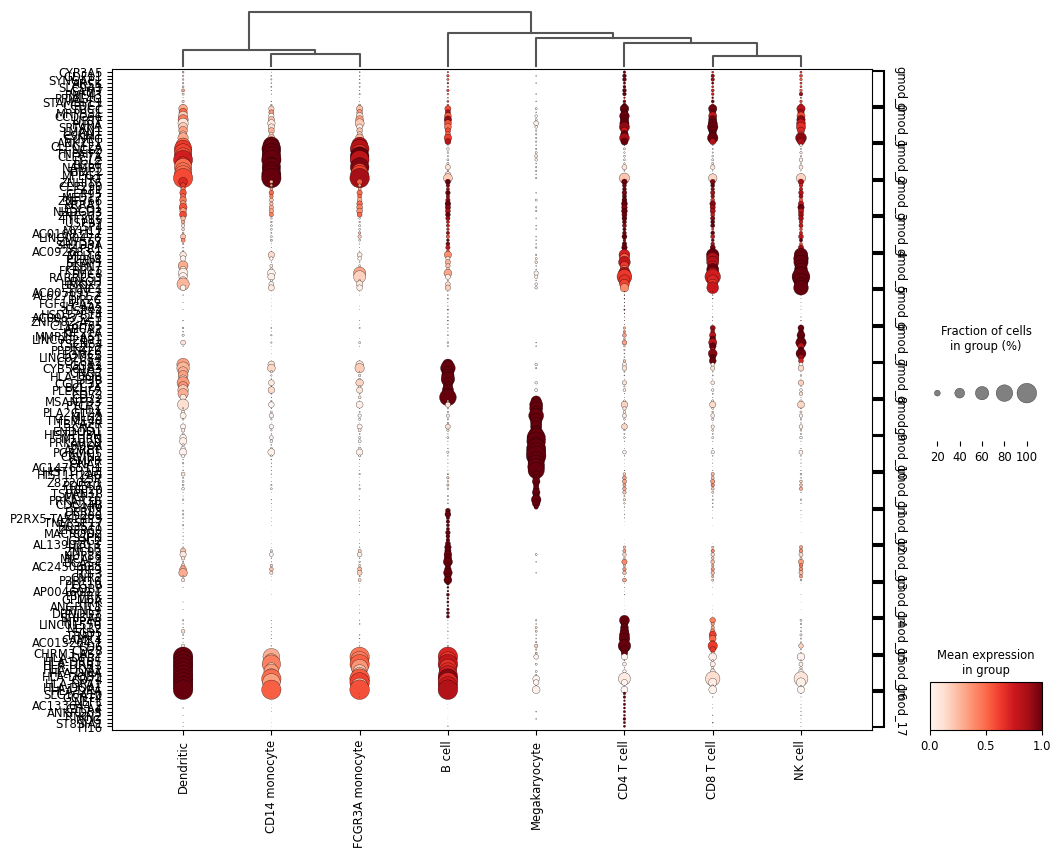

In [15]:
# Build a combined gene list for the dotplot, grouped by module
gene_dict = {mod: genes for mod, genes in top_genes.items() if len(genes) > 0}

sc.pl.dotplot(
    adata,
    var_names=gene_dict,
    groupby='cell_type',
    standard_scale='var',
    swap_axes=True,
    figsize=(12, max(4, len(gene_dict) * 0.5)),
    dendrogram=True,
)

### Matrixplot of top module genes

A matrixplot provides a compact, tile-based view of mean expression per group. The grouping of genes by module is immediately apparent.

categories: B cell, CD14 monocyte, CD4 T cell, etc.
var_group_labels: gmod_0, gmod_1, gmod_2, etc.


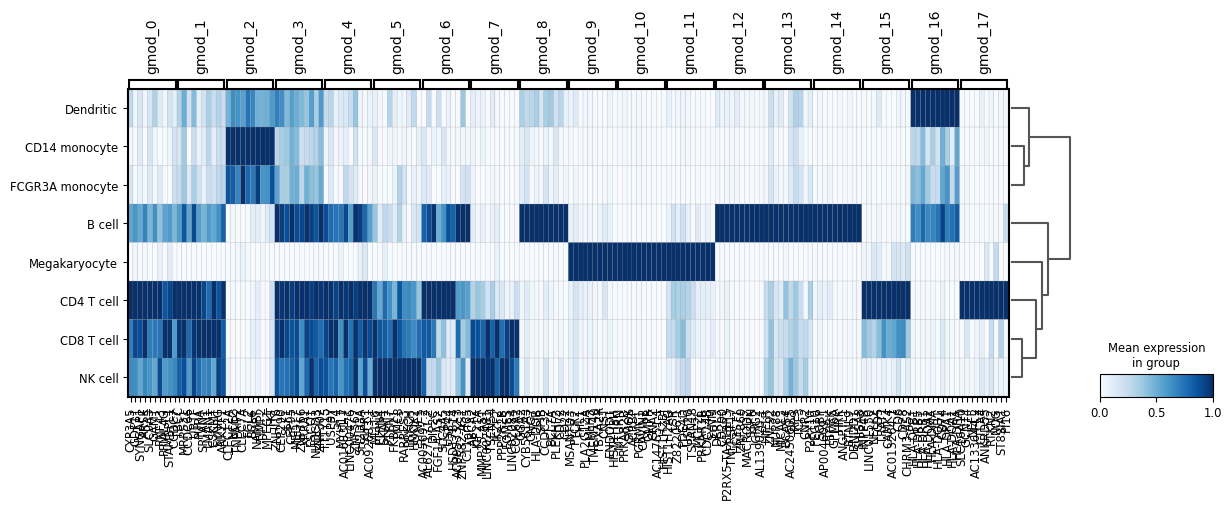

In [16]:
sc.pl.matrixplot(
    adata,
    var_names=gene_dict,
    groupby='cell_type',
    standard_scale='var',
    cmap='Blues',
    figsize=(14, 4),
    dendrogram=True,
)

---
## Step 5: Module-PC correlation

Each principal component captures a direction of variation in the data. By correlating module scores with individual PCs, we can see which axes of variation a module drives. A module that strongly correlates with a high-variance PC likely reflects a major biological axis (e.g. myeloid vs. lymphoid identity).

In [17]:
# Correlate the first module's score with all PCs
example_mod = obs_score_names[0]
pc_corr = cn.tl.correlate_module_scores_with_pcs(
    adata,
    score_key=example_mod,
    method='pearson',
    min_abs_corr=0.3,
)

print(f"Module: {module_names[0]}")
pc_corr.head(10)

Module: gmod_0


,pc,pc_index,correlation,abs_correlation,p_value,variance_ratio,n_cells,score_key,flag_high_corr
0,PC1,1,-0.829723,0.829723,0.000000e+00,0.243175,10309,score_gmod_0,True
1,PC2,2,-0.171147,0.171147,1.327383e-68,0.084327,10309,score_gmod_0,False
2,PC3,3,-0.168813,0.168813,9.084741e-67,0.037764,10309,score_gmod_0,False
3,PC5,5,-0.085906,0.085906,2.384241e-18,0.012687,10309,score_gmod_0,False
4,PC6,6,-0.081503,0.081503,1.151221e-16,0.010735,10309,score_gmod_0,False
5,PC7,7,0.068012,0.068012,4.758403e-12,0.006724,10309,score_gmod_0,False
6,PC11,11,0.067554,0.067554,6.601760e-12,0.003347,10309,score_gmod_0,False
7,PC14,14,-0.057007,0.057007,6.949889e-09,0.002502,10309,score_gmod_0,False
8,PC8,8,0.050413,0.050413,3.035931e-07,0.005359,10309,score_gmod_0,False
9,PC22,22,-0.041877,0.041877,2.106686e-05,0.001749,10309,score_gmod_0,False


### Visualize module-PC correlations for all modules

Below we compute correlations for every module against the top PCs and display the result as a heatmap. Strong blocks along certain PCs can reveal the main biological axes captured by each module.

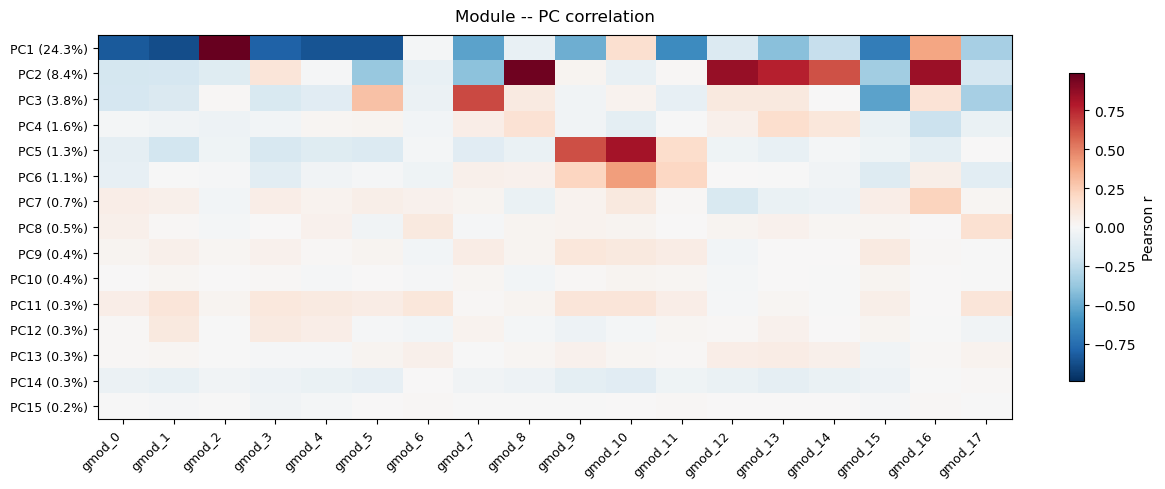

In [18]:
# Compute correlations for all modules
n_pcs_show = 15
corr_matrix = pd.DataFrame(index=[f'PC{i+1}' for i in range(n_pcs_show)], columns=module_names, dtype=float)

for mod_name, obs_name in zip(module_names, obs_score_names):
    df = cn.tl.correlate_module_scores_with_pcs(adata, score_key=obs_name, sort=False)
    corr_matrix[mod_name] = df['correlation'].values[:n_pcs_show]

# Get variance ratios for labeling
vr = adata.uns['pca']['variance_ratio'][:n_pcs_show]
pc_labels = [f'PC{i+1} ({vr[i]:.1%})' for i in range(n_pcs_show)]

fig, ax = plt.subplots(figsize=(max(6, len(module_names) * 0.7), 5))
vmax = np.abs(corr_matrix.values).max()
im = ax.imshow(corr_matrix.values.astype(float), cmap='RdBu_r', aspect='auto', vmin=-vmax, vmax=vmax)

ax.set_xticks(range(len(module_names)))
ax.set_xticklabels(module_names, rotation=45, ha='right', fontsize=9)
ax.set_yticks(range(n_pcs_show))
ax.set_yticklabels(pc_labels, fontsize=9)
ax.set_title('Module -- PC correlation', fontsize=12, pad=10)

plt.colorbar(im, ax=ax, label='Pearson r', shrink=0.8)
plt.tight_layout()
plt.show()

---
## Step 6: Tuning the resolution

The `leiden_resolution` parameter is the main knob for controlling how many modules are discovered. Let's explore the effect of different resolutions.

- **Low resolution** (e.g. 0.1) yields fewer, larger modules that capture broad programs
- **High resolution** (e.g. 2.0) yields many small modules that may capture very specific co-expression

In [19]:
resolutions = [0.1, 0.25, 0.5, 1.0, 2.0]
res_results = {}

for res in resolutions:
    mods = cn.tl.find_gene_modules(
        adata,
        mean_cluster=True,
        groupby='leiden',
        mask_var='highly_variable',
        knn=5,
        leiden_resolution=res,
        min_module_size=5,
        uns_key=f'modules_res{res}',
    )
    sizes = [len(g) for g in mods.values()]
    res_results[res] = {
        'n_modules': len(mods),
        'median_size': int(np.median(sizes)) if sizes else 0,
        'min_size': min(sizes) if sizes else 0,
        'max_size': max(sizes) if sizes else 0,
    }

res_df = pd.DataFrame(res_results).T
res_df.index.name = 'resolution'
res_df

,n_modules,median_size,min_size,max_size
resolution,,,,
0.10,7,195,13,896
0.25,11,154,11,398
0.50,18,105,11,247
1.00,34,56,9,126
2.00,48,39,9,90


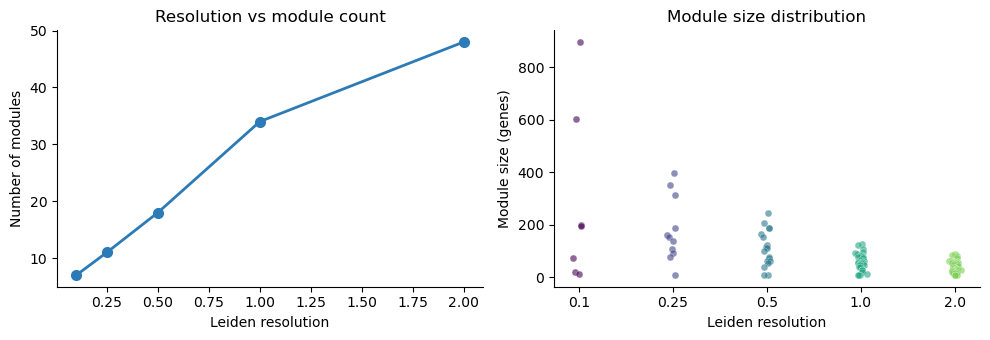

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

# Left: number of modules vs resolution
axes[0].plot(res_df.index, res_df['n_modules'], 'o-', color='#2c7bb6', linewidth=2, markersize=7)
axes[0].set_xlabel('Leiden resolution')
axes[0].set_ylabel('Number of modules')
axes[0].set_title('Resolution vs module count')
axes[0].spines[['top', 'right']].set_visible(False)

# Right: module size distribution per resolution
for i, res in enumerate(resolutions):
    key = f'modules_res{res}'
    sizes = [len(g) for g in adata.uns[key].values()]
    jitter = np.random.default_rng(42).normal(0, 0.03, len(sizes))
    axes[1].scatter(
        [i + j for j in jitter],
        sizes,
        alpha=0.6,
        s=25,
        color=plt.cm.viridis(i / len(resolutions)),
        edgecolors='white',
        linewidth=0.3,
    )

axes[1].set_xticks(range(len(resolutions)))
axes[1].set_xticklabels([str(r) for r in resolutions])
axes[1].set_xlabel('Leiden resolution')
axes[1].set_ylabel('Module size (genes)')
axes[1].set_title('Module size distribution')
axes[1].spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

---
## Step 7: Comparing scoring methods

It can be useful to compare value-based and rank-based scoring to see how robust the module activity estimates are. Below we compare the default value-based mean with UCell and AUCell scores for one module.

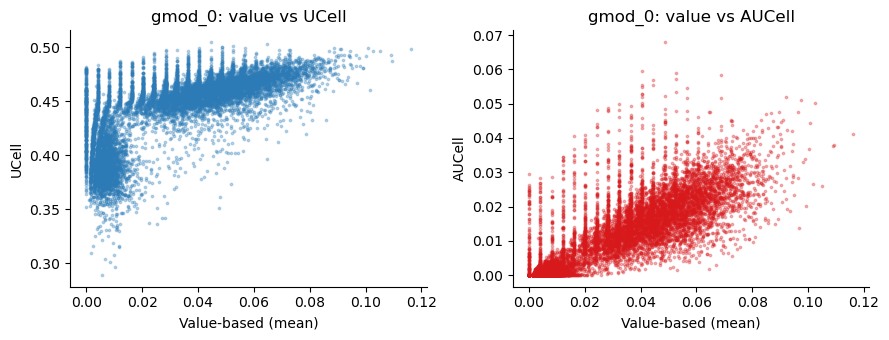

In [21]:
# Restore the modules from our preferred resolution
# (find_gene_modules overwrites adata.uns['knn_modules'] above,
#  so let's re-run at 0.5 or pick from the resolution sweep)
modules = adata.uns['modules_res0.5']
adata.uns['knn_modules'] = modules

# Score with three methods
s_val = cn.tl.score_gene_sets(adata, gene_sets=modules, agg='mean', clip_percentiles=(1, 99))
s_ucell = cn.tl.score_gene_sets(adata, gene_sets=modules, rank_method='ucell')
s_auc = cn.tl.score_gene_sets(adata, gene_sets=modules, rank_method='auc', auc_max_rank=0.1)

# Compare for the first module
mod0 = list(modules.keys())[0]

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))

axes[0].scatter(s_val[mod0], s_ucell[mod0], s=3, alpha=0.3, color='#2c7bb6')
axes[0].set_xlabel(f'Value-based (mean)')
axes[0].set_ylabel(f'UCell')
axes[0].set_title(f'{mod0}: value vs UCell')
axes[0].spines[['top', 'right']].set_visible(False)

axes[1].scatter(s_val[mod0], s_auc[mod0], s=3, alpha=0.3, color='#d7191c')
axes[1].set_xlabel(f'Value-based (mean)')
axes[1].set_ylabel(f'AUCell')
axes[1].set_title(f'{mod0}: value vs AUCell')
axes[1].spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

---
## Summary

| Step | Function | Output |
|---|---|---|
| Discover modules | `cn.tl.find_gene_modules()` | Dict of gene lists in `adata.uns['knn_modules']` |
| Score cells | `cn.tl.score_gene_sets()` | Per-cell scores (DataFrame or `adata.obsm`) |
| Query genes | `cn.tl.what_module_has_gene()`, `cn.tl.whoare_genes_neighbors()` | Module names, neighbor lists |
| Top genes | `cn.tl.subset_modules_top_genes()` | Compact gene lists per module |
| PC correlation | `cn.tl.correlate_module_scores_with_pcs()` | DataFrame of correlations per PC |
| Visualize | `cn.pl.heatmap_scores()`, `cn.pl.dotplot_scn_scores()`, scanpy plots | Figures |

**Key parameter choices to keep in mind:**

- `leiden_resolution` controls the granularity of modules -- try a few values and examine the results
- `mean_cluster=True` is faster and less noisy for most datasets
- `mask_var='highly_variable'` focuses on informative genes; using all genes can produce noise-driven modules
- For robust cross-dataset comparisons, prefer rank-based scoring (`rank_method='ucell'`)